<a href="https://colab.research.google.com/github/alan-d-smith/neurotech-notebooks/blob/main/SVM_Kernels_Regression_Workshop.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Regression, Support Vector Machines and Kernels KCL Neurotech Workshop By Matylda
In this notebook you will learn to predict a baby's **age** from the **size of its brain**, using a few classic machine learning methods:

1. **Linear regression**: fitting a straight line
2. **Measuring error** fairly with RMSE, a test set and cross-validation
3. **Non-linear data**: what to do when a straight line isn't enough
4. **Support Vector Machines (SVM)** for classification: margins and support vectors
5. **The kernel trick**: making curved decisions with a linear method
6. **Support Vector Regression (SVR)** and **Kernel Ridge Regression**
7. **Putting it all together**: comparing and tuning models

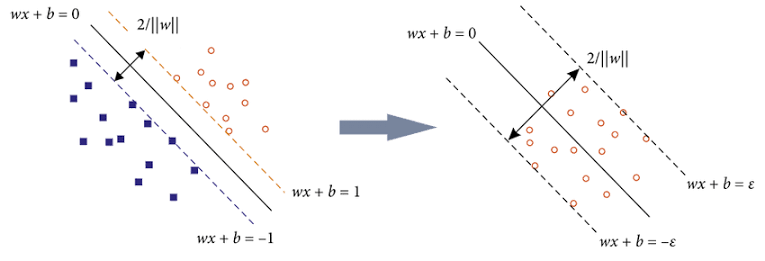

**How to use this notebook in Google Colab**
* Run cells **in order from top to bottom**. Click a cell and press **Shift + Enter** to run it.
* **Try it** cells have sliders or values you can change to see what happens.
* **Exercise** cells ask you to write or edit a little code. Click **Show answer** if you get stuck.
* The data are built into the notebook, so you don't need to upload any files.
* If something breaks, use **Runtime → Restart and run all**.

## The dataset
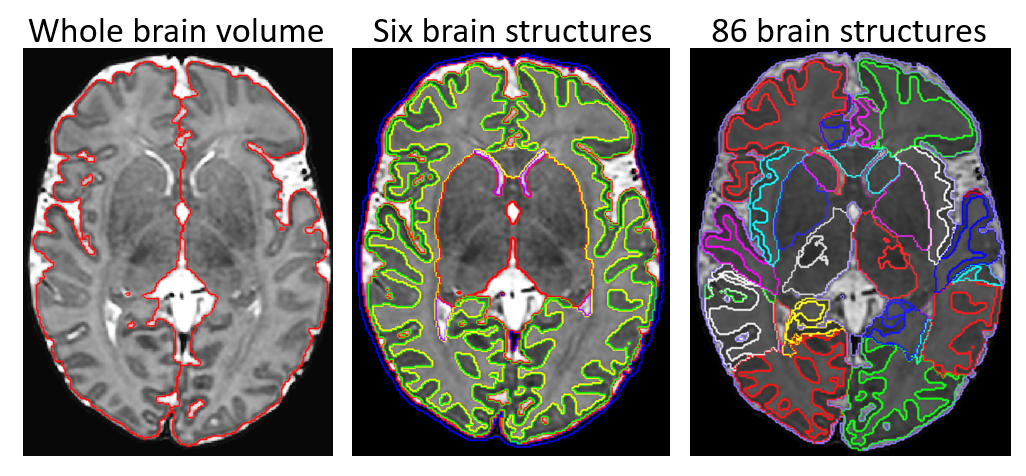

The data are generated here in the script to resemble data that came from MRI scans of **164 newborn babies**, many of them born early (preterm).  Each brain was automatically split into structures, and the volume of each structure was measured.

The thing we want to predict (the **target**) is the baby's **gestational age (GA) at scan, in weeks**. A full-term pregnancy is about 40 weeks.

We will use three versions of the data:

| File | Features (inputs) |
|---|---|
| `GA-brain-volumes-1-feature.csv` | whole brain volume |
| `GA-brain-volumes-6-features.csv` | 6 main structures: cortical grey matter, cortical white matter, myelinated white matter, subcortical grey matter, cerebellum, brainstem |
| `GA-brain-volumes-myelin.csv` | volume of myelinated tissue |

In every file, **column 0 is the age** and the remaining columns are the volumes.

## Step 0: Set up

First we import the libraries we need:
* **numpy**: maths with arrays
* **pandas**: tables of data
* **matplotlib**: plots
* **scikit-learn** (`sklearn`): the machine learning models

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, cross_val_score, KFold, StratifiedKFold, GridSearchCV
from sklearn.metrics import mean_squared_error
from sklearn.svm import SVC, SVR
from sklearn.kernel_ridge import KernelRidge
from sklearn.datasets import make_circles

from ipywidgets import interact, FloatLogSlider, FloatSlider, IntSlider

plt.rcParams['figure.figsize'] = (6, 4)
print('All libraries loaded!')

All libraries loaded!


In [2]:
#@title ▶ Run this cell to create the data files (read it of you're interested) { display-mode: "form" }
DATA = {
'GA-brain-volumes-1-feature.csv': """
35.714,252.41
37.429,277.73
36.143,266.36
36.714,266.13
42.286,308.35
40.143,303.76
34.429,227.46
36.857,329.92
37,268.49
37,296
37,253.23
35.143,263.67
41,419.91
35,267.12
33.286,172.06
35.143,274.15
35,221.65
34,215.68
36.714,280.97
34.857,231.97
45.143,395.03
45.143,369.38
34.714,243.35
40.429,383.89
37.286,287.6
40,351.39
36.857,322.83
36.857,335.82
34.857,246.86
41.286,330.47
37,308.63
37.143,286.99
36.714,265.54
36.714,269.6
37.571,325.1
35,254.59
43,430.68
35.143,243.52
39.857,321.85
36.857,264.67
41.143,422.28
36.857,299.02
36.857,240.28
41.286,433.98
32.143,199.39
41.286,426.71
32.286,200.38
34,231.64
34,223.65
39.857,351.67
32.714,191.89
41,362.34
32.714,179.71
43.571,415.6
35.571,282.31
42.714,460.72
38.143,215
38.143,284.21
34.714,257.23
35.429,267.33
39.714,361.19
35.714,280.65
40,392.42
29.857,128.16
38.429,260.32
35.714,245.19
40.143,361.29
36.429,313.79
39.714,419.37
35.571,219.04
42,374.51
35.571,225.07
36.857,276.6
39.571,349.79
36.857,286.36
39.571,352.89
37.143,300.58
34,271.46
37.429,296.74
35.714,244.39
38.429,310.77
36.714,280.33
36.714,286.03
36.286,223.28
42.857,355.15
32.714,144.41
42.857,301.25
33.571,198.82
40.857,356.72
32.429,158.68
41.714,332.08
33.286,198.53
42.286,415.34
33.286,185.33
42.286,399.85
29.286,125.24
35.286,219.63
35.429,241.44
41.429,390.33
36.143,313.78
35.286,213.58
44.286,398.78
44.286,384.13
35.857,181.03
42.143,301.71
32.571,227.53
32.571,185.37
34.571,261.94
34.143,255.12
41.286,415.95
34.143,220.8
40.143,365.05
29.857,131.89
32.143,177.5
43.143,401.18
37,299.13
34.143,221.13
42,402.26
31.571,123.66
41.143,337.92
35.286,274.07
43.143,436.9
29,111.92
36.143,281.92
44.143,447.23
29.857,153.76
40.857,370.54
30.857,158.6
39,322.07
30,103.42
38.429,224.73
36.571,255.39
30,187.09
31,130.2
41.571,330.29
33.429,193.64
39.714,330.19
35,247.59
40,343.7
27.286,95.172
43.857,324.52
39.571,336.86
44.143,406.98
44.143,422.06
33.714,221.45
41.571,396.99
26.571,96.333
31.429,194.58
39.286,362.89
33.714,185.86
29.286,139.35
30.429,149.71
39.429,332.77
38.286,327.1
38.286,316.5
32.857,207.28
35.714,260.97
35.714,255.51
43,392.52
40.857,344.04
34.857,196.4
34.429,232.43
40.429,428.26
35.429,307.99
""",
'GA-brain-volumes-6-features.csv': """
35.714,85.687,123.59,6.317,14.99,14.75,4.97
37.429,102.01,127.36,6.722,16.062,18.05,5.35
36.143,94.009,126.86,6.577,15.768,16.16,5.18
36.714,95.295,123.59,6.785,16.696,16.85,5.33
42.286,140.89,112.36,7.341,17.46,22.565,5.47
40.143,121.88,131.53,6.98,18.18,17.63,5.45
34.429,75.978,112.58,5.784,14.371,12.27,4.6
36.857,117.57,157.74,7.235,19.68,19.39,5.92
37,99.077,124.89,6.11,16.455,14.93,5.07
37,103.97,139.58,8.211,17.081,18.79,5.88
37,86.857,116.67,7.021,16.603,18.05,5.73
35.143,89.601,129.05,6.337,16.765,14.91,5.2
41,175.46,172.02,9.15,23.335,30.252,6.97
35,90.102,128.79,6.378,16.265,17.87,5.72
33.286,51.476,89.35,4.702,11.931,9.7,4.03
35.143,93.898,130.61,6.775,17.064,17.69,5.84
35,75.835,107.47,5.638,13.761,12.9,4.34
34,69.837,107.78,5.772,14.012,12.05,4.59
36.714,110.26,122.4,7.095,17.32,16.22,5.31
34.857,75.554,116.5,5.893,14.237,13.4,4.68
45.143,182.43,143.38,8.615,20.546,30.251,7.16
45.143,164.36,137.42,8.269,20.207,29.839,6.6
34.714,78.335,124.61,6.129,14.181,13.54,4.77
40.429,157.82,161.43,8.441,21.382,25.986,6.23
37.286,103.81,132.3,6.986,17.944,18.67,5.6
40,148.93,132.11,8.995,21.591,30.764,6.97
36.857,119.49,149.38,7.926,19.632,18.59,5.71
36.857,124.7,153.24,8.114,19.937,20.907,6.19
34.857,81.317,123.63,6.373,14.722,13.8,5
41.286,139.51,128.35,8.038,20.662,24.774,6.69
37,109.6,145.25,7.307,18.967,19.2,5.96
37.143,114.36,122.58,6.803,16.161,19.38,5.37
36.714,89.861,127.25,6.676,15.344,19.22,5.7
36.714,92.687,128.55,6.477,15.753,18.99,5.6
37.571,123.17,149.42,7.884,17.954,18.42,5.79
35,88.161,122.96,6.779,15.8,14.23,5.12
43,193.86,163.15,9.426,23.627,30.644,6.98
35.143,84.642,115.8,6.734,15.254,14.45,4.98
39.857,129.9,132.44,7.852,19.954,23.03,6.52
36.857,92.41,129.23,6.614,15.033,14.16,5.03
41.143,179.12,170.53,9.023,23.432,29.804,7.28
36.857,114.62,130.11,7.398,19.311,19.846,5.72
36.857,91.235,104.09,6.346,15.682,16.29,5.04
41.286,182.85,177.63,9.77,25.245,28.699,6.86
32.143,58.404,108.25,5.266,12.797,8.79,4.07
41.286,180.31,175,9.451,24.397,28.121,6.75
32.286,58.644,109.95,5.261,12.151,8.96,4.05
34,73.891,117.65,6.143,14.42,12.76,5.03
34,72.366,111.6,6.014,14.112,12.91,5.04
39.857,144.95,148.6,7.555,19.874,22.465,5.92
32.714,60.144,98.511,5.286,13.111,9.45,4.17
41,148.51,151.03,8.405,21.774,24.151,6.28
32.714,51.236,97.457,4.8257,12.48,8.94,3.82
43.571,181.35,158.73,8.635,22.989,33.966,7.04
35.571,99.274,135.62,6.951,16.219,16.54,5.56
42.714,204.57,174.96,10.525,25.637,33.769,7.81
38.143,85.502,96.679,5.083,12.097,10.13,4.15
38.143,105.14,134.18,6.398,16.747,15.1,4.68
34.714,83.237,132.66,5.816,15.86,13.12,4.87
35.429,91.161,132.26,6.533,15.13,15.23,5.01
39.714,141.34,160.12,8.41,19.923,23.012,6.1
35.714,99.954,135.79,6.707,16.303,14.9,5.22
40,163.72,166.24,8.513,21.16,23.679,6.46
29.857,33.626,72.716,3.4499,8.3398,5.86,3.05
38.429,100.16,112.91,6.503,15.592,17.85,5.23
35.714,85.397,116.94,6.555,14.695,14.79,5.03
40.143,148.96,149.55,8.228,20.449,25.17,6.46
36.429,112.58,147.79,7.825,19.398,18.26,5.95
39.714,168.88,177.96,9.717,24.86,28.016,7.36
35.571,74.979,103.18,6.126,14.187,14.09,4.77
42,164.47,142.05,8.46,21.953,27.798,6.85
35.571,79.485,104.44,6.353,13.765,14.26,5.15
36.857,97.269,132.56,6.317,16.143,16.89,5.15
39.571,135.8,154.83,7.712,19.302,23.656,5.85
36.857,101.24,138.51,6.341,16.211,16.99,5.04
39.571,137.79,156.31,7.275,19.601,23.72,5.73
37.143,117.14,131.99,7.337,18.047,17.84,5.8
34,84.188,144.25,6.855,16.596,12.44,5
37.429,108.56,136.65,7.843,18.132,17.7,5.84
35.714,88.675,113.98,6.224,14.928,13.75,4.58
38.429,123.97,134.59,6.716,18.133,19.41,5.24
36.714,100.1,128.29,7.152,16.842,19.81,6.08
36.714,103.2,130.87,7.415,16.647,19.55,6.09
36.286,75.984,108.24,5.635,14.257,12.94,4.53
42.857,154.56,140.39,7.747,20.72,23.376,5.82
32.714,44.379,73.156,3.658,9.7885,8.76,3.37
42.857,129.7,110.02,6.921,18.825,27.697,5.69
33.571,60.767,102.6,5.254,12.959,11.38,4.24
40.857,145.13,147.21,8.174,20.858,26.626,6.33
32.429,48.764,81.828,4.08,9.9761,9.17,3.66
41.714,144.93,129.7,7.677,18.712,23.119,5.93
33.286,61.016,103.68,5.253,12.678,10.4,4.19
42.286,178.76,174.67,9.252,23.128,20.564,6.48
33.286,57.346,95.257,5.154,12.144,10.02,4.12
42.286,169.71,163.93,9.026,22.362,25.74,6.68
29.286,33.29,71.529,3.545,7.8618,5.19,2.99
35.286,74.118,103.69,6.207,15.214,13.8,4.93
35.429,85.658,114.42,5.991,14.591,14.37,5.07
41.429,168.17,153.84,8.984,22.955,26.773,7.15
36.143,112.24,147.03,7.565,19.036,19.32,6.12
35.286,71.612,104.34,6.137,12.737,12.28,4.4
44.286,183.45,143.72,8.796,22.571,30.214,7.08
44.286,174.78,139.87,8.511,21.253,30.067,6.83
35.857,61.334,82.882,4.909,11.754,14.4,4.33
42.143,123.1,117.55,6.658,18.052,27.963,6.04
32.571,68.844,119.1,6.158,14.224,12.65,4.6
32.571,56.464,96.422,4.955,12.082,10.01,3.82
34.571,86.459,132.05,6.378,15.652,14.2,5.26
34.143,81.501,129.32,6.048,16.284,14.8,5.17
41.286,179.29,164.63,8.961,23.358,29.514,6.75
34.143,71.426,112.91,5.494,13.604,11.82,4.33
40.143,146.79,157.82,7.87,19.771,24.42,5.98
29.857,39.652,69.986,3.315,8.5913,6.62,3.04
32.143,51.351,94.202,4.851,12.135,9.43,4.26
43.143,176.63,150.74,8.745,23.841,31.385,7.01
37,108.24,137.99,7.579,18.776,19.04,5.76
34.143,69.282,113.17,6.379,13.948,12.68,4.52
42,168.76,163.46,9.68,24.482,26.67,6.6
31.571,36.42,65.619,3.532,8.4743,5.9,2.81
41.143,134.4,147.78,7.022,19.487,21.793,5.46
35.286,97.195,130,6.795,16.406,16.35,5.43
43.143,198.51,162.13,9.682,24.278,31.569,7.13
29,31.067,60.958,3.9417,7.4837,4.96,2.78
36.143,104.12,132.17,6.744,16.512,15.37,5.57
44.143,199.21,171.22,9.941,23.815,33.278,7.18
29.857,41.565,86.248,4.414,9.618,7.4,3.5
40.857,154.03,150.4,8.326,21.597,26.608,6.67
30.857,44.325,87.766,4.382,9.6404,7.65,3.3
39,131.72,137.66,6.959,17.7,19.883,5.52
30,29.661,55.046,3.5085,6.5262,5.26,2.69
38.429,86.885,97.402,6.016,13.707,14.77,4.44
36.571,92.159,116.55,7.422,16.224,15.9,5.27
30,47.814,109.51,5.03,11.691,7.71,3.82
31,35.799,71.899,3.9447,8.8086,5.41,3.23
41.571,135.71,137.83,7.86,19.215,21.547,6.03
33.429,62.468,95.401,5.746,12.358,12.09,4.38
39.714,136.54,130.06,8.512,20.654,26.155,6.13
35,80.634,126.31,6.082,14.785,12.74,4.89
40,139.15,145.5,7.969,19.734,22.922,6.32
27.286,24.941,53.483,2.7258,6.8484,4.24,2.3
43.857,152.99,128.59,7.503,19.934,8.04,5.38
39.571,134.14,146.31,8.027,19.844,20.163,6.18
44.143,180.36,150.11,9.239,24.437,32.764,7.18
44.143,187.67,154.93,9.732,25.39,34.034,7.45
33.714,71.291,109.49,6.072,14.782,13.35,4.97
41.571,164.01,164.12,9.539,23.012,26.264,6.84
26.571,25.321,55.477,2.8173,6.2173,3.42,2.34
31.429,59.329,103.46,4.9694,12.201,9.16,4.06
39.286,153.84,147.66,7.987,19.863,24.301,6.68
33.714,61.888,89.346,4.628,13.077,11.54,4.18
29.286,38.025,79.628,3.6775,7.9384,5.81,3.16
30.429,38.563,86.406,4.2358,9.1476,6.63,3.42
39.429,130.83,144.25,7.558,19.657,21.92,6.29
38.286,124.65,145.74,8.05,19.628,20.341,6.13
38.286,118.79,141.71,7.984,19.254,20.483,5.85
32.857,59.574,115.81,4.73,12.857,9.24,3.68
35.714,88.585,126.52,6.449,16.763,15.72,5.04
35.714,86.869,122.82,6.804,16.537,15.7,4.99
43,170.33,154.6,8.523,22.27,27.047,6.78
40.857,144.02,143.46,7.862,19.416,21.046,5.85
34.857,66.201,96.496,5.581,12.018,10.74,4.08
34.429,78.264,115.54,5.304,13.636,13.51,4.49
40.429,170.47,184.91,9.183,23.651,29.266,7.3
35.429,100.49,156.46,7.083,18.257,17.42,6.01
""",
'GA-brain-volumes-myelin.csv': """
35.714,0.264
37.429,0.286
36.143,0.386
36.714,0.31
42.286,0.465
40.143,0.328
34.429,0.211
36.857,0.386
37,0.267
37,0.241
37,0.299
35.143,0.239
41,0.533
35,0.227
33.286,0.129
35.143,0.241
35,0.201
34,0.154
36.714,0.333
34.857,0.188
45.143,0.516
45.143,0.527
34.714,0.224
40.429,0.606
37.286,0.303
40,0.554
36.857,0.304
36.857,0.379
34.857,0.162
41.286,0.423
37,0.298
37.143,0.338
36.714,0.271
36.714,0.303
37.571,0.328
35,0.27
43,0.602
35.143,0.299
39.857,0.404
36.857,0.266
41.143,0.657
36.857,0.32
36.857,0.281
41.286,0.627
32.143,0.119
41.286,0.635
32.286,0.148
34,0.185
34,0.186
39.857,0.401
32.714,0.179
41,0.504
32.714,0.0977
43.571,0.553
35.571,0.282
42.714,0.512
38.143,0.173
38.143,0.336
34.714,0.217
35.429,0.212
39.714,0.386
35.714,0.267
40,0.566
29.857,0.0799
38.429,0.306
35.714,0.253
40.143,0.429
36.429,0.241
39.714,0.531
35.571,0.206
42,0.527
35.571,0.238
36.857,0.347
39.571,0.458
36.857,0.331
39.571,0.463
37.143,0.338
34,0.226
37.429,0.27
35.714,0.251
38.429,0.318
36.714,0.283
36.714,0.284
36.286,0.255
42.857,0.605
32.714,0.127
42.857,0.348
33.571,0.157
40.857,0.485
32.429,0.098
41.714,0.453
33.286,0.166
42.286,0.683
33.286,0.15
42.286,0.66
29.286,0.0931
35.286,0.183
35.429,0.187
41.429,0.604
36.143,0.316
35.286,0.144
44.286,0.74
44.286,0.605
35.857,0.184
42.143,0.421
32.571,0.182
32.571,0.164
34.571,0.25
34.143,0.229
41.286,0.617
34.143,0.181
40.143,0.444
29.857,0.11
32.143,0.159
43.143,0.592
37,0.34
34.143,0.164
42,0.601
31.571,0.107
41.143,0.511
35.286,0.314
43.143,0.564
29,0.0652
36.143,0.304
44.143,0.789
29.857,0.114
40.857,0.554
30.857,0.109
39,0.413
30,0.108
38.429,0.267
36.571,0.266
30,0.114
31,0.0787
41.571,0.562
33.429,0.158
39.714,0.473
35,0.219
40,0.446
27.286,0.0674
43.857,0.532
39.571,0.47
44.143,0.578
44.143,0.546
33.714,0.218
41.571,0.628
26.571,0.0837
31.429,0.0879
39.286,0.432
33.714,0.167
29.286,0.0955
30.429,0.0886
39.429,0.338
38.286,0.391
38.286,0.382
32.857,0.162
35.714,0.269
35.714,0.295
43,0.505
40.857,0.499
34.857,0.169
34.429,0.176
40.429,0.499
35.429,0.313
""",
}

for name, text in DATA.items():
    with open(name, 'w') as f:
        f.write(text.strip() + '\n')
print('Created:', ', '.join(DATA))

Created: GA-brain-volumes-1-feature.csv, GA-brain-volumes-6-features.csv, GA-brain-volumes-myelin.csv


Now we load the three files into **DataFrames** (tables) and give the columns readable names.

In [3]:
whole = pd.read_csv('GA-brain-volumes-1-feature.csv', header=None,
                    names=['GA', 'brain_volume'])
six = pd.read_csv('GA-brain-volumes-6-features.csv', header=None,
                  names=['GA', 'cortical_GM', 'cortical_WM', 'myelinated_WM',
                         'subcortical_GM', 'cerebellum', 'brainstem'])
myelin = pd.read_csv('GA-brain-volumes-myelin.csv', header=None,
                     names=['GA', 'myelin_volume'])

print('Number of babies:', len(whole))
six.head()   # show the first 5 rows

Number of babies: 164


,GA,cortical_GM,cortical_WM,myelinated_WM,subcortical_GM,cerebellum,brainstem
0,35.714,85.687,123.59,6.317,14.990,14.750,4.97
1,37.429,102.010,127.36,6.722,16.062,18.050,5.35
2,36.143,94.009,126.86,6.577,15.768,16.160,5.18
3,36.714,95.295,123.59,6.785,16.696,16.850,5.33
4,42.286,140.890,112.36,7.341,17.460,22.565,5.47


---
# Part 1: Linear regression

**Regression** means predicting a *number*, here the age in weeks.

The simplest model is a **straight line**:

$$\hat{y} = w_0 + w_1 x$$

* $x$ is the **feature** (brain volume)
* $\hat{y}$ ("y-hat") is the **predicted** age
* $w_1$ is the **slope**: how many weeks of age go with each extra unit of volume
* $w_0$ is the **intercept**: where the line crosses the y-axis

"Training" the model means finding the $w_0$ and $w_1$ that make the line fit the data as closely as possible. For linear regression, that means making the **squared errors** between predictions and true ages as small as possible.

Let's look at the data first.

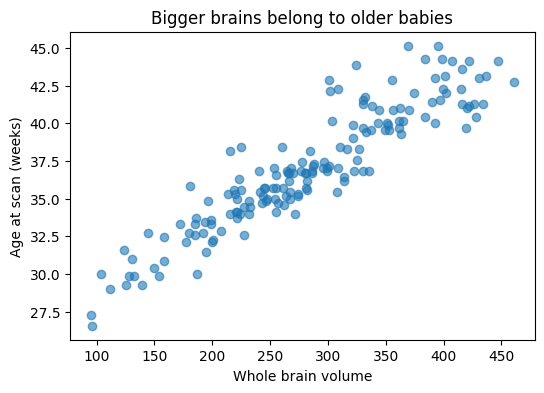

In [4]:
X = whole[['brain_volume']].values   # features: a table with one column
y = whole['GA'].values               # target: ages in weeks

plt.scatter(X, y, alpha=0.6)
plt.xlabel('Whole brain volume')
plt.ylabel('Age at scan (weeks)')
plt.title('Bigger brains belong to older babies')
plt.show()

The points roughly follow a straight line. Let's fit one with scikit-learn. Every sklearn model works the same way:
1. **Create** the model: `model = LinearRegression()`
2. **Fit** it to the data: `model.fit(X, y)`
3. **Predict**: `model.predict(X_new)`

Slope w1     = 0.0432
Intercept w0 = 24.82


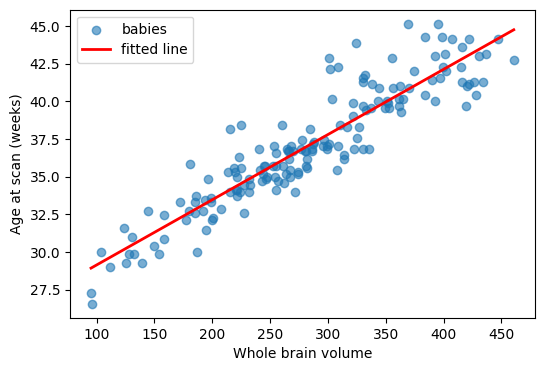

In [5]:
model = LinearRegression()
model.fit(X, y)

print('Slope w1     =', round(model.coef_[0], 4))
print('Intercept w0 =', round(model.intercept_, 2))

# draw the fitted line on top of the data
x_line = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
plt.scatter(X, y, alpha=0.6, label='babies')
plt.plot(x_line, model.predict(x_line), 'r', linewidth=2, label='fitted line')
plt.xlabel('Whole brain volume')
plt.ylabel('Age at scan (weeks)')
plt.legend()
plt.show()

**Try it:** predict the age of a new baby. Change `new_volume` and run the cell again.

In [7]:
new_volume = 300
prediction = model.predict([[new_volume]])[0]
print(f'A baby with brain volume {new_volume} is predicted to be {prediction:.1f} weeks old')

A baby with brain volume 300 is predicted to be 37.8 weeks old


## How good is the model? RMSE

We measure error with the **Root Mean Squared Error (RMSE)**:

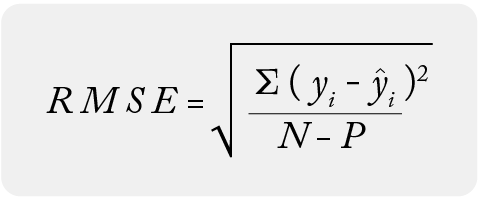

In words: take each error, square it, average the squares, then take the square root. The nice thing is that RMSE is in the **same units as the target**, so here it is in **weeks**. Smaller is better.

In [8]:
y_pred = model.predict(X)
rmse = np.sqrt(mean_squared_error(y, y_pred))
print(f'RMSE on the data we trained on: {rmse:.2f} weeks')

RMSE on the data we trained on: 1.56 weeks


## A fair test: training data vs. new data

The RMSE above is a bit of a cheat: we measured it on the **same babies the model learned from**. What we really care about is how well the model does on babies it has **never seen**.

The simplest fix is to hide some data:
* **Training set** (75%): the model learns from these
* **Test set** (25%): kept aside and used only to measure the error

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
print('Training babies:', len(X_train), '| Test babies:', len(X_test))

model = LinearRegression().fit(X_train, y_train)

rmse_train = np.sqrt(mean_squared_error(y_train, model.predict(X_train)))
rmse_test  = np.sqrt(mean_squared_error(y_test,  model.predict(X_test)))
print(f'Training RMSE: {rmse_train:.2f} weeks')
print(f'Test RMSE:     {rmse_test:.2f} weeks')

Training babies: 123 | Test babies: 41
Training RMSE: 1.58 weeks
Test RMSE:     1.55 weeks


## Cross-validation: an even fairer test

With only 164 babies, a single test set is small, and the result depends on *which* babies happened to land in it. **Cross-validation** fixes this:

1. Split the data into 5 equal parts (**folds**)
2. Train on 4 folds, test on the 5th
3. Repeat 5 times, so that every fold gets a turn as the test set
4. Average the 5 test errors

```
Round 1:  [TEST] [train] [train] [train] [train]
Round 2:  [train] [TEST] [train] [train] [train]
...
Round 5:  [train] [train] [train] [train] [TEST]
```

We'll use cross-validated RMSE (**CV RMSE**) for the rest of the workshop. The helper function below does all of this for us.

In [11]:
CV = KFold(n_splits=5, shuffle=True, random_state=0)   # the same 5 folds every time

def rmse_cv(model, X, y):
    """Average RMSE over 5-fold cross-validation (in weeks)."""
    scores = cross_val_score(model, X, y, cv=CV, scoring='neg_root_mean_squared_error')
    return -scores.mean()   # sklearn returns negative errors, so we flip the sign

print(f'Linear regression, whole brain volume: CV RMSE = {rmse_cv(LinearRegression(), X, y):.2f} weeks')

Linear regression, whole brain volume: CV RMSE = 1.60 weeks


### Exercise 1: does using more brain structures help?

The `six` table has 6 brain structures. Add more column names to the `features` list and see how the CV RMSE changes.

The column names are: `'cortical_GM', 'cortical_WM', 'myelinated_WM', 'subcortical_GM', 'cerebellum', 'brainstem'`

In [12]:
features = ['cortical_GM', 'cortical_WM', 'myelinated_WM', 'subcortical_GM', 'cerebellum', 'brainstem']          # TASK: add more column names to this list

X6 = six[features].values
y6 = six['GA'].values
print(f'Features used: {features}')
print(f'CV RMSE = {rmse_cv(LinearRegression(), X6, y6):.2f} weeks')

Features used: ['cortical_GM', 'cortical_WM', 'myelinated_WM', 'subcortical_GM', 'cerebellum', 'brainstem']
CV RMSE = 1.22 weeks


<details>
<summary><b>Show answer</b></summary>

```python
features = ['cortical_GM', 'cortical_WM', 'myelinated_WM',
            'subcortical_GM', 'cerebellum', 'brainstem']
```
Cortical grey matter on its own (about **1.28 weeks**) already beats whole brain volume (about **1.60 weeks**), and using all six structures brings the error down to about **1.22 weeks**. Different structures grow at different rates, so together they carry more information about age.
</details>

---
# Part 2: When a straight line isn't enough

Now let's try to predict age from the volume of **myelinated tissue** (myelin is the fatty insulation around nerve fibres, and it builds up quickly around birth).

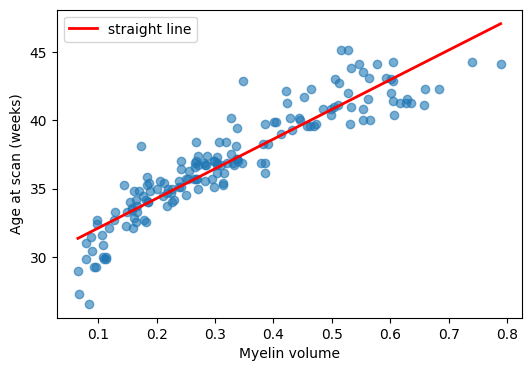

Straight line: CV RMSE = 1.58 weeks


In [13]:
Xm = myelin[['myelin_volume']].values
ym = myelin['GA'].values

lin = LinearRegression().fit(Xm, ym)
x_line = np.linspace(Xm.min(), Xm.max(), 200).reshape(-1, 1)

plt.scatter(Xm, ym, alpha=0.6)
plt.plot(x_line, lin.predict(x_line), 'r', linewidth=2, label='straight line')
plt.xlabel('Myelin volume')
plt.ylabel('Age at scan (weeks)')
plt.legend()
plt.show()
print(f'Straight line: CV RMSE = {rmse_cv(LinearRegression(), Xm, ym):.2f} weeks')

The data **bend**: age rises quickly at small myelin volumes, then levels off. A straight line is too simple, so it **underfits** (its errors are systematic, not just random noise).

### One fix: make new features

We can still use linear regression if we first create extra features such as $x^2$ and $x^3$:

$$\hat{y} = w_0 + w_1 x + w_2 x^2 + w_3 x^3$$

The model is still *linear in the weights* $w$, but the curve it draws is no longer straight. This idea of **transforming the features and then fitting something linear** is the key idea behind kernels, which we'll meet in Part 4.

### Pipelines and scaling

Below we chain three steps into a **pipeline** with `make_pipeline`:
1. `PolynomialFeatures(degree=3)` creates $x, x^2, x^3$
2. `StandardScaler()` rescales every feature to mean 0 and standard deviation 1, so that no feature dominates just because its numbers are bigger. **SVMs and kernel methods need this too.**
3. `LinearRegression()` fits the model

A pipeline behaves like a single model: you can call `.fit()` and `.predict()` on it.

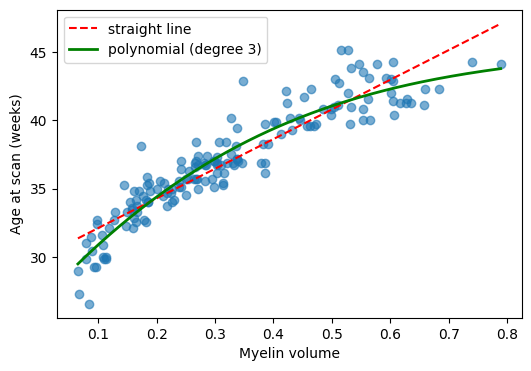

Polynomial: CV RMSE = 1.38 weeks


In [14]:
poly = make_pipeline(PolynomialFeatures(degree=3), StandardScaler(), LinearRegression())
poly.fit(Xm, ym)

plt.scatter(Xm, ym, alpha=0.6)
plt.plot(x_line, lin.predict(x_line), 'r--', label='straight line')
plt.plot(x_line, poly.predict(x_line), 'g', linewidth=2, label='polynomial (degree 3)')
plt.xlabel('Myelin volume')
plt.ylabel('Age at scan (weeks)')
plt.legend()
plt.show()
print(f'Polynomial: CV RMSE = {rmse_cv(poly, Xm, ym):.2f} weeks')

 **Try it:** change `degree` to 1, 2, 5, 10 and 15. When does the curve start to look silly? A very flexible model starts to follow the random noise. This is called **overfitting**, and the CV RMSE goes back up.

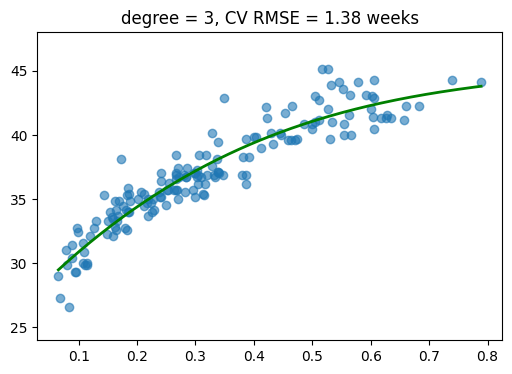

In [19]:
degree = 3   # TASK: change this value and see what happens

m = make_pipeline(PolynomialFeatures(degree=degree), StandardScaler(), LinearRegression()).fit(Xm, ym)
plt.scatter(Xm, ym, alpha=0.6)
plt.plot(x_line, m.predict(x_line), 'g', linewidth=2)
plt.ylim(24, 48)
plt.title(f'degree = {degree}, CV RMSE = {rmse_cv(m, Xm, ym):.2f} weeks')
plt.show()

---
# Part 3: Support Vector Machines (SVM) for classification

SVMs can do both **classification** (predicting a category) and **regression** (predicting a number). We'll start with classification because it's easier to picture.

### A new question

Was the baby scanned **at term** (37 weeks or older) or **preterm** (younger than 37 weeks)? We'll answer it using two features: **cortical grey matter** and **cortical white matter** volume.

term
preterm (0)    90
term (1)       74
Name: count, dtype: int64


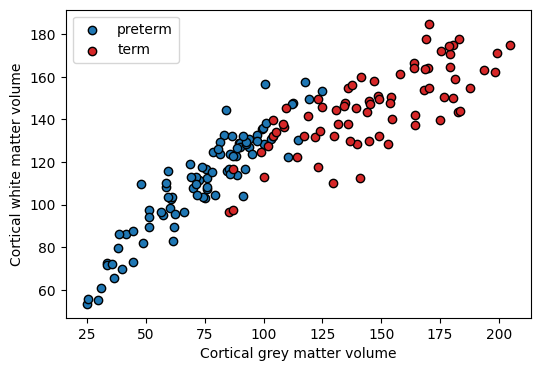

In [20]:
six['term'] = (six['GA'] >= 37).astype(int)       # 1 = term, 0 = preterm
Xc = six[['cortical_GM', 'cortical_WM']].values
yc = six['term'].values

print(six['term'].value_counts().rename({0: 'preterm (0)', 1: 'term (1)'}))

plt.scatter(Xc[yc == 0, 0], Xc[yc == 0, 1], c='tab:blue', label='preterm', edgecolors='k')
plt.scatter(Xc[yc == 1, 0], Xc[yc == 1, 1], c='tab:red',  label='term',    edgecolors='k')
plt.xlabel('Cortical grey matter volume')
plt.ylabel('Cortical white matter volume')
plt.legend()
plt.show()

## How an SVM works



An SVM looks for the **best dividing line** (the **decision boundary**) between the two classes:

* The decision boundary is $\mathbf{w}^T\mathbf{x} + b = 0$ (the red line). $\mathbf{w}$ is a vector that points at right angles to the line, and $b$ shifts it.
* Two **marginal planes** sit parallel to it, one on each side: $\mathbf{w}^T\mathbf{x} + b = +1$ and $\mathbf{w}^T\mathbf{x} + b = -1$ (the dashed lines).
* The gap between them is the **margin**, and its width is $\dfrac{2}{\|\mathbf{w}\|}$.
* The SVM picks the line with the **widest margin**: the safest separation, as far as possible from both classes.
* The points lying on (or inside) the margin are the **support vectors**. They alone decide where the line goes; you could delete every other point and get the same answer.

### Hard margin vs. soft margin

If the classes can be separated perfectly, we want every point on the correct side of its plane: $y_i(\mathbf{w}^T\mathbf{x}_i + b) \ge 1$ (with labels $y_i = \pm 1$). Maximising the margin $2/\|\mathbf{w}\|$ is the same as **minimising** $\|\mathbf{w}\|$, so the **hard margin** cost function is:

$$\min_{\mathbf{w},b}\ \frac{\|\mathbf{w}\|^2}{2}$$

(We square it because that is smoother and easier to optimise.)

Real data overlap, so a perfect split is usually impossible. A **soft margin** lets some points break the rules, and charges a penalty $\xi_i$ ("xi") for each one, equal to how far the point is on the wrong side of its plane:

$$\min_{\mathbf{w},b}\ \frac{\|\mathbf{w}\|^2}{2} + C\sum_{i=1}^{N}\xi_i$$

**C** is a setting you choose (a **hyperparameter**):
* **small C**: mistakes are cheap, so the margin is wide and many points become support vectors (smoother, simpler model)
* **large C**: mistakes are expensive, so the margin is narrow and the model tries hard to classify every training point (risk of overfitting)

The next cell defines a plotting helper. You don't need to understand it; just run it.

In [ ]:
def plot_svm(model, X, y, title='', labels=('class 0', 'class 1')):
    """Draw the SVM decision boundary (solid), margins (dashed) and support vectors (circled)."""
    pad0, pad1 = np.ptp(X[:, 0]) * 0.05, np.ptp(X[:, 1]) * 0.05
    g0 = np.linspace(X[:, 0].min() - pad0, X[:, 0].max() + pad0, 300)
    g1 = np.linspace(X[:, 1].min() - pad1, X[:, 1].max() + pad1, 300)
    G0, G1 = np.meshgrid(g0, g1)
    Z = model.decision_function(np.c_[G0.ravel(), G1.ravel()]).reshape(G0.shape)

    plt.contourf(G0, G1, Z > 0, alpha=0.15, cmap='coolwarm')
    plt.contour(G0, G1, Z, levels=[-1, 0, 1], colors='k', linestyles=['--', '-', '--'])
    plt.scatter(X[y == 0, 0], X[y == 0, 1], c='tab:blue', edgecolors='k', label=labels[0])
    plt.scatter(X[y == 1, 0], X[y == 1, 1], c='tab:red', edgecolors='k', label=labels[1])
    svm = model[-1] if hasattr(model, 'steps') else model     # works for pipelines too
    sv = svm.support_
    plt.scatter(X[sv, 0], X[sv, 1], s=160, facecolors='none', edgecolors='k',
                linewidths=1.5, label=f'support vectors ({len(sv)})')
    plt.legend(fontsize=8, loc='best')
    plt.title(title)

CV_CLF = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

def accuracy_cv(model, X, y):
    """Average fraction of correct predictions over 5-fold cross-validation."""
    return cross_val_score(model, X, y, cv=CV_CLF, scoring='accuracy').mean()

Now let's fit a **linear SVM**. We put a `StandardScaler` in front, because SVMs measure distances and need features on the same scale.

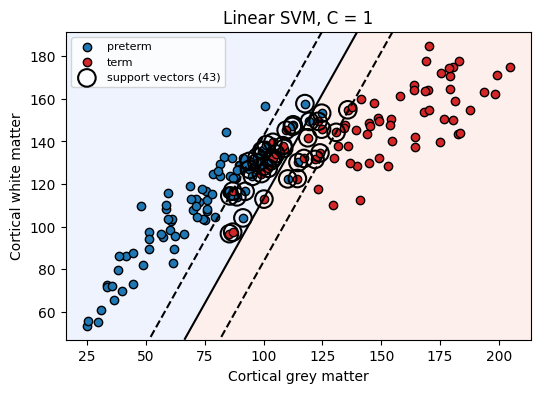

Cross-validated accuracy: 90.3%


In [ ]:
svm_lin = make_pipeline(StandardScaler(), SVC(kernel='linear', C=1))
svm_lin.fit(Xc, yc)

plot_svm(svm_lin, Xc, yc, title='Linear SVM, C = 1', labels=('preterm', 'term'))
plt.xlabel('Cortical grey matter'); plt.ylabel('Cortical white matter')
plt.show()
print(f'Cross-validated accuracy: {accuracy_cv(svm_lin, Xc, yc):.1%}')

### Try it: the effect of C

Drag the slider to change **C**. Watch the dashed margin lines and the number of support vectors.

In [ ]:
def show_C(C=1.0):
    m = make_pipeline(StandardScaler(), SVC(kernel='linear', C=C)).fit(Xc, yc)
    plot_svm(m, Xc, yc, title=f'C = {C:.3g}   |   CV accuracy = {accuracy_cv(m, Xc, yc):.1%}', labels=('preterm', 'term'))
    plt.xlabel('Cortical grey matter'); plt.ylabel('Cortical white matter')
    plt.show()

interact(show_C, C=FloatLogSlider(value=1, base=10, min=-3, max=3, step=0.25, continuous_update=False));

interactive(children=(FloatLogSlider(value=1.0, continuous_update=False, description='C', max=3.0, min=-3.0, s…

<details>
<summary><b>What should you notice?</b></summary>

* **Small C** (e.g. 0.001): a very wide margin and lots of support vectors. The model barely cares about mistakes.
* **Large C** (e.g. 1000): a narrow margin and few support vectors. The model works hard to put training points on the right side.
* The accuracy changes much less than the picture does. The best C is usually somewhere in the middle, and we find it with cross-validation.
</details>

### Exercise 2: find the best C

Complete the loop so that it prints the cross-validated accuracy for each value of C. Which C works best?

In [ ]:
for C in [0.001, 0.01, 0.1, 1, 10, 100]:
    model = make_pipeline(StandardScaler(), SVC(kernel='linear', C=C))
    acc = ...        # replace ... with a call to accuracy_cv
    print(f'C = {C:<6}  accuracy = {acc}')

C = 0.001   accuracy = Ellipsis
C = 0.01    accuracy = Ellipsis
C = 0.1     accuracy = Ellipsis
C = 1       accuracy = Ellipsis
C = 10      accuracy = Ellipsis
C = 100     accuracy = Ellipsis


<details>
<summary><b>Show answer</b></summary>

```python
    acc = accuracy_cv(model, Xc, yc)
    print(f'C = {C:<6}  accuracy = {acc:.1%}')
```
Very small C does worst, because the margin is so wide that the boundary is pushed around. From about C = 0.1 upwards the accuracy is around 90%: two brain volumes can tell term from preterm babies correctly about 9 times out of 10.
</details>

---
# Part 4: The kernel trick

So far our SVM drew a **straight** line. What if the classes can't be separated by a straight line at all? Here is a made-up example: one class forms a ring around the other.

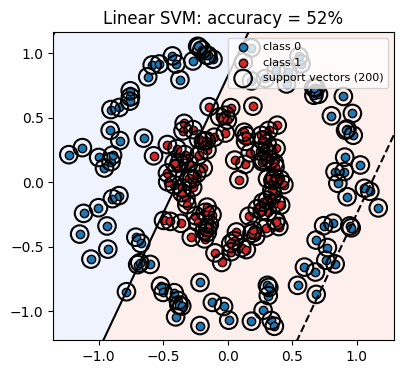

In [ ]:
Xr, yr = make_circles(n_samples=200, factor=0.4, noise=0.1, random_state=0)

ring_lin = SVC(kernel='linear', C=1).fit(Xr, yr)
plot_svm(ring_lin, Xr, yr, title=f'Linear SVM: accuracy = {accuracy_cv(ring_lin, Xr, yr):.0%}')
plt.gca().set_aspect('equal')
plt.show()

A straight line can do no better than guessing (about 50%).

### Idea: add a new feature

What if we add a third feature, the squared distance from the centre: $z = x_1^2 + x_2^2$? The inner points have small $z$ and the outer ring has large $z$. In 3D, the two classes sit at different heights, and a **flat plane** separates them easily.

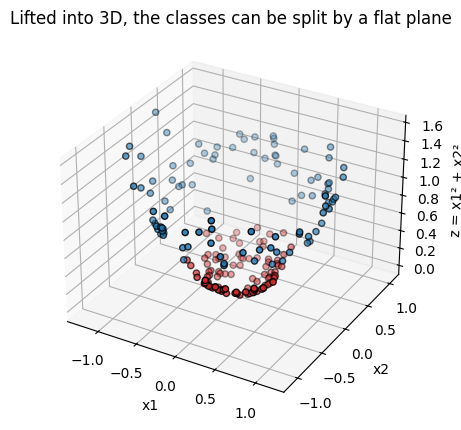

In [ ]:
z = Xr[:, 0]**2 + Xr[:, 1]**2

fig = plt.figure(figsize=(7, 5))
ax = fig.add_subplot(projection='3d')
ax.scatter(Xr[yr == 0, 0], Xr[yr == 0, 1], z[yr == 0], c='tab:blue', edgecolors='k')
ax.scatter(Xr[yr == 1, 0], Xr[yr == 1, 1], z[yr == 1], c='tab:red', edgecolors='k')
ax.set_xlabel('x1'); ax.set_ylabel('x2'); ax.set_zlabel('z = x1² + x2²')
ax.set_title('Lifted into 3D, the classes can be split by a flat plane')
plt.show()

### Kernels do this for you

Inventing the right extra features by hand is hard. A **kernel** does it automatically. A kernel $\kappa(\mathbf{x}, \mathbf{z})$ is a **similarity score** between two data points. Using a kernel is mathematically the same as mapping the data into a higher-dimensional space and fitting a straight boundary there, **without ever computing the new features**. That shortcut is the **kernel trick**.

Common kernels in scikit-learn:

| Kernel | Formula | Good for |
|---|---|---|
| `'linear'` | $\mathbf{x}^T\mathbf{z}$ | straight boundaries (what we used above) |
| `'poly'` | $(\gamma\,\mathbf{x}^T\mathbf{z} + r)^d$ | polynomial-shaped boundaries |
| `'rbf'` (Gaussian) | $\exp(-\gamma\,\|\mathbf{x}-\mathbf{z}\|^2)$ | most curved problems; **the usual first choice** |
| `'sigmoid'` | $\tanh(\gamma\,\mathbf{x}^T\mathbf{z} + r)$ | inspired by neural networks; used less often |

The **RBF kernel** says two points are similar if they are close together. The setting **gamma** ($\gamma$) controls how far each point's influence reaches:
* **small gamma**: wide reach, smooth boundary (can underfit)
* **large gamma**: short reach, wiggly boundary that wraps around single points (can overfit)

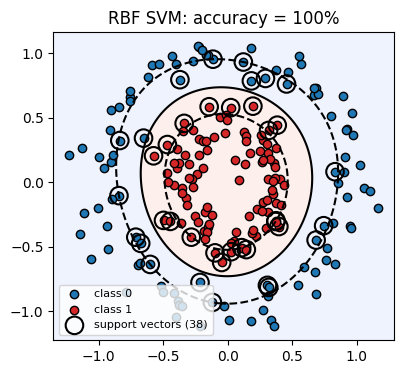

In [ ]:
ring_rbf = SVC(kernel='rbf', C=1, gamma=1).fit(Xr, yr)
plot_svm(ring_rbf, Xr, yr, title=f'RBF SVM: accuracy = {accuracy_cv(ring_rbf, Xr, yr):.0%}')
plt.gca().set_aspect('equal')
plt.show()

### Try it: gamma and C for the RBF kernel

Try a very small gamma (0.01), then a very large one (100). Then try a large gamma with a large C.

In [ ]:
def show_rbf(gamma=1.0, C=1.0):
    m = SVC(kernel='rbf', gamma=gamma, C=C).fit(Xr, yr)
    plot_svm(m, Xr, yr, title=f'gamma = {gamma:.3g}, C = {C:.3g}  |  CV accuracy = {accuracy_cv(m, Xr, yr):.0%}')
    plt.gca().set_aspect('equal')
    plt.show()

interact(show_rbf,
         gamma=FloatLogSlider(value=1, base=10, min=-2, max=2, step=0.25, continuous_update=False),
         C=FloatLogSlider(value=1, base=10, min=-2, max=3, step=0.25, continuous_update=False));

interactive(children=(FloatLogSlider(value=1.0, continuous_update=False, description='gamma', max=2.0, min=-2.…

<details>
<summary><b>What should you notice?</b></summary>

* **gamma = 0.01**: the boundary is almost straight, so the model underfits.
* **gamma = 100**: the boundary breaks into little islands around individual points. Training points are classified perfectly, but the cross-validated accuracy drops, so the model overfits.
* Raising **C** at high gamma makes overfitting worse, because the model is also punished harder for each training mistake.
</details>

### Back to the babies

Let's compare all four kernels on our term/preterm problem.

  linear kernel: CV accuracy = 90.3%
    poly kernel: CV accuracy = 83.0%
     rbf kernel: CV accuracy = 89.7%
 sigmoid kernel: CV accuracy = 90.9%


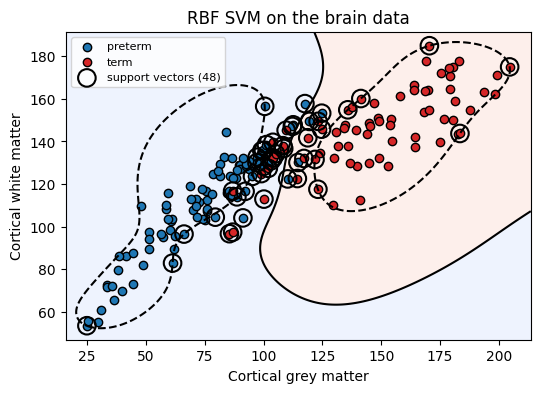

In [ ]:
for kernel in ['linear', 'poly', 'rbf', 'sigmoid']:
    m = make_pipeline(StandardScaler(), SVC(kernel=kernel, C=1))
    print(f'{kernel:>8} kernel: CV accuracy = {accuracy_cv(m, Xc, yc):.1%}')

svm_rbf = make_pipeline(StandardScaler(), SVC(kernel='rbf', C=1, gamma=1)).fit(Xc, yc)
plot_svm(svm_rbf, Xc, yc, title='RBF SVM on the brain data', labels=('preterm', 'term'))
plt.xlabel('Cortical grey matter'); plt.ylabel('Cortical white matter')
plt.show()

**Take-home message:** a kernel only helps when the true boundary is curved. For term vs. preterm, a straight line already works about as well as anything else, so the simpler linear model is the sensible choice. Always compare with a simple baseline!

Also look at the RBF plot's empty corners (e.g. bottom right, where there are no babies at all). The boundary takes odd shapes there, because the model has no data to guide it. Flexible models can behave strangely outside the range of the training data.

---
# Part 5: Support Vector Regression (SVR)

SVMs can predict numbers too. **Support Vector Regression** fits a line (or curve) with a **tube** of width $\varepsilon$ ("epsilon") around it:

* Points **inside the tube** count as "close enough" and cost nothing.
* Points **outside the tube** are penalised by $\xi_i$, their distance from the edge of the tube.
* The points on or outside the tube edge are the **support vectors**.

The cost function looks very similar to the soft-margin SVM:

$$\min_{\mathbf{w},b}\ \frac{\|\mathbf{w}\|^2}{2} + C\sum_{i=1}^{N}\xi_i \qquad \text{such that} \qquad |y_i - (\mathbf{w}^T\mathbf{x}_i + b)| \le \varepsilon + \xi_i$$

The settings:
* **epsilon**: tube width, in the same units as the target (here **weeks**). `epsilon=1` means errors under one week are ignored.
* **C**: how strongly points outside the tube are penalised.
* **kernel** and **gamma**: exactly as before, they let the fitted line bend.

Run the plotting helper first.

In [ ]:
def plot_svr(model, X, y, title=''):
    """Plot an SVR fit with its epsilon-tube (dashed) and support vectors (circled)."""
    svr = model[-1] if hasattr(model, 'steps') else model
    xs = np.linspace(X.min(), X.max(), 300).reshape(-1, 1)
    pred = model.predict(xs)
    plt.scatter(X, y, alpha=0.5, label='babies')
    plt.plot(xs, pred, 'r', linewidth=2, label='SVR prediction')
    plt.plot(xs, pred + svr.epsilon, 'r--', linewidth=1, label=f'tube (epsilon = {svr.epsilon:g})')
    plt.plot(xs, pred - svr.epsilon, 'r--', linewidth=1)
    sv = svr.support_
    plt.scatter(X[sv], y[sv], s=80, facecolors='none', edgecolors='k', label=f'support vectors ({len(sv)})')
    plt.ylim(24, 48)
    plt.xlabel('Myelin volume'); plt.ylabel('Age at scan (weeks)')
    plt.legend(fontsize=8)
    plt.title(title)

First, a **linear** SVR on the myelin data, and then one with an **RBF kernel**.

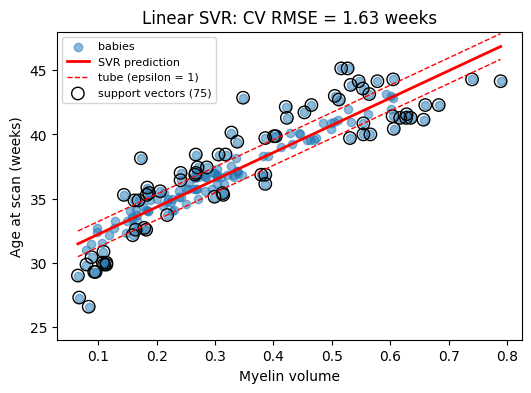

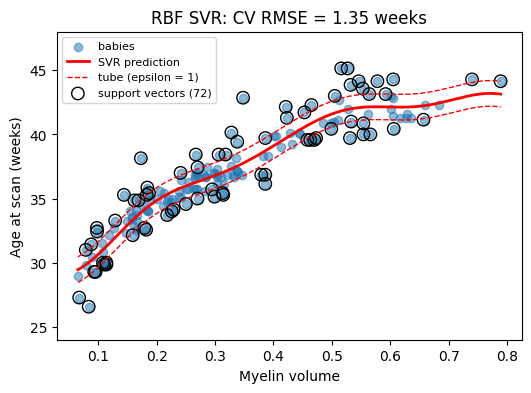

In [ ]:
svr_lin = make_pipeline(StandardScaler(), SVR(kernel='linear', C=10, epsilon=1))
svr_lin.fit(Xm, ym)
plot_svr(svr_lin, Xm, ym, title=f'Linear SVR: CV RMSE = {rmse_cv(svr_lin, Xm, ym):.2f} weeks')
plt.show()

svr_rbf = make_pipeline(StandardScaler(), SVR(kernel='rbf', C=10, gamma=1, epsilon=1))
svr_rbf.fit(Xm, ym)
plot_svr(svr_rbf, Xm, ym, title=f'RBF SVR: CV RMSE = {rmse_cv(svr_rbf, Xm, ym):.2f} weeks')
plt.show()

The RBF kernel lets the SVR follow the bend in the data, and the error drops.

###Try it: epsilon, C and gamma

* Make **epsilon** bigger: what happens to the number of support vectors?
* Make **gamma** very large: does the curve start chasing noise?
* Make **C** very small: does the curve still follow the data?

In [ ]:
def show_svr(epsilon=1.0, C=10.0, gamma=1.0):
    m = make_pipeline(StandardScaler(), SVR(kernel='rbf', C=C, gamma=gamma, epsilon=epsilon)).fit(Xm, ym)
    plot_svr(m, Xm, ym, title=f'CV RMSE = {rmse_cv(m, Xm, ym):.2f} weeks')
    plt.show()

interact(show_svr,
         epsilon=FloatSlider(value=1, min=0.1, max=4, step=0.1, continuous_update=False),
         C=FloatLogSlider(value=10, base=10, min=-2, max=3, step=0.25, continuous_update=False),
         gamma=FloatLogSlider(value=1, base=10, min=-2, max=2, step=0.25, continuous_update=False));

interactive(children=(FloatSlider(value=1.0, continuous_update=False, description='epsilon', max=4.0, min=0.1)…

<details>
<summary><b>What should you notice?</b></summary>

* **Bigger epsilon**: a wider tube, so more points fit inside and there are **fewer support vectors**. If the tube is too wide, the model stops caring about errors and gets worse.
* **Large gamma**: the curve wiggles to follow individual points (overfitting).
* **Small C**: errors are cheap, so the curve flattens and underfits.
</details>

---
# Part 6: Kernel Ridge Regression

Kernels are not just for SVMs. **Kernel Ridge Regression (KRR)** combines a kernel with ordinary least-squares regression:

* Like linear regression, it tries to make the **squared error of every point** small. There is no tube, so every point counts.
* Like **ridge regression**, it adds a penalty on large weights, controlled by **alpha**. Bigger alpha gives a smoother curve.
* Its prediction for a new point $\mathbf{x}$ is a weighted sum of similarities to all the training points:

$$\hat{y} = \sum_{i=1}^{N} a_i\,\kappa(\mathbf{x}, \mathbf{x}_i)$$

So a new baby's predicted age is built from how similar its brain is to each baby we have already seen.

**SVR vs. KRR in one line:** SVR ignores small errors and depends only on its support vectors; KRR uses every point.

*Technical note:* KRR has no intercept $b$. To stop it pulling predictions towards 0 weeks, we subtract the average age before fitting and add it back afterwards. The small wrapper below does that.

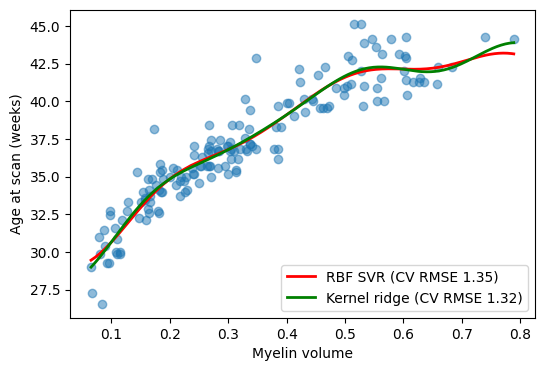

In [ ]:
from sklearn.compose import TransformedTargetRegressor

def kernel_ridge(alpha=1.0, gamma=1.0):
    """Scaled RBF Kernel Ridge Regression that also centres the target (ages)."""
    krr = make_pipeline(StandardScaler(), KernelRidge(kernel='rbf', alpha=alpha, gamma=gamma))
    return TransformedTargetRegressor(regressor=krr, transformer=StandardScaler(with_std=False))

krr = kernel_ridge(alpha=0.1, gamma=1).fit(Xm, ym)

plt.scatter(Xm, ym, alpha=0.5)
plt.plot(x_line, svr_rbf.predict(x_line), 'r', linewidth=2, label=f'RBF SVR (CV RMSE {rmse_cv(svr_rbf, Xm, ym):.2f})')
plt.plot(x_line, krr.predict(x_line), 'g', linewidth=2, label=f'Kernel ridge (CV RMSE {rmse_cv(krr, Xm, ym):.2f})')
plt.xlabel('Myelin volume'); plt.ylabel('Age at scan (weeks)')
plt.legend()
plt.show()

### Try it: kernel width

In KRR (and SVR), **gamma** sets the width of each point's "bump" of influence. Try a tiny alpha with a large gamma: each baby gets its own spike, which is a classic case of overfitting.

In [ ]:
def show_krr(gamma=1.0, alpha=0.1):
    m = kernel_ridge(alpha=alpha, gamma=gamma).fit(Xm, ym)
    plt.scatter(Xm, ym, alpha=0.5)
    plt.plot(x_line, m.predict(x_line), 'g', linewidth=2)
    plt.ylim(24, 48)
    plt.xlabel('Myelin volume'); plt.ylabel('Age at scan (weeks)')
    plt.title(f'gamma = {gamma:.3g}, alpha = {alpha:.3g}  |  CV RMSE = {rmse_cv(m, Xm, ym):.2f} weeks')
    plt.show()

interact(show_krr,
         gamma=FloatLogSlider(value=1, base=10, min=-2, max=3, step=0.25, continuous_update=False),
         alpha=FloatLogSlider(value=0.1, base=10, min=-5, max=2, step=0.5, continuous_update=False));

interactive(children=(FloatLogSlider(value=1.0, continuous_update=False, description='gamma', max=3.0, min=-2.…

---
# Part 7: Putting it all together

Let's go back to predicting age from all **six brain structures** and compare:
1. Linear regression
2. SVR with an RBF kernel
3. Kernel Ridge Regression with an RBF kernel

### Tuning with grid search

Each kernel method has settings (C, gamma, epsilon, alpha) that we shouldn't guess. **`GridSearchCV`** tries every combination from a list, scores each one with cross-validation, and keeps the best. To refer to a setting inside a pipeline, you write the step name, two underscores, then the setting, e.g. `svr__C`.

**Tip:** if the best value turns out to be at the very end of your list (e.g. the biggest C you tried), widen the list and search again, because the true best value may lie beyond it.

In [ ]:
X6 = six[['cortical_GM', 'cortical_WM', 'myelinated_WM',
          'subcortical_GM', 'cerebellum', 'brainstem']].values
y6 = six['GA'].values

# 1. Linear regression: nothing to tune
rmse_lin = rmse_cv(LinearRegression(), X6, y6)
print(f'Linear regression: CV RMSE = {rmse_lin:.2f} weeks')

# 2. SVR: try every combination of these settings (5 x 4 x 3 = 60 models)
svr_grid = GridSearchCV(
    make_pipeline(StandardScaler(), SVR(kernel='rbf')),
    param_grid={'svr__C': [1, 10, 100, 1000, 10000],
                'svr__gamma': [0.001, 0.01, 0.1, 1],
                'svr__epsilon': [0.1, 0.5, 1]},
    cv=CV, scoring='neg_root_mean_squared_error')
svr_grid.fit(X6, y6)
rmse_svr = -svr_grid.best_score_
print(f'SVR (RBF):         CV RMSE = {rmse_svr:.2f} weeks   best settings: {svr_grid.best_params_}')

Linear regression: CV RMSE = 1.22 weeks
SVR (RBF):         CV RMSE = 0.78 weeks   best settings: {'svr__C': 10000, 'svr__epsilon': 0.5, 'svr__gamma': 0.01}


In [ ]:
# 3. Kernel ridge regression
krr_grid = GridSearchCV(
    kernel_ridge(),
    param_grid={'regressor__kernelridge__alpha': [0.0001, 0.001, 0.01, 0.1, 1],
                'regressor__kernelridge__gamma': [0.001, 0.01, 0.1, 1]},
    cv=CV, scoring='neg_root_mean_squared_error')
krr_grid.fit(X6, y6)
rmse_krr = -krr_grid.best_score_
print(f'Kernel ridge (RBF): CV RMSE = {rmse_krr:.2f} weeks   best settings: {krr_grid.best_params_}')

Kernel ridge (RBF): CV RMSE = 0.79 weeks   best settings: {'regressor__kernelridge__alpha': 0.001, 'regressor__kernelridge__gamma': 0.01}


Linear regression     1.22
SVR (RBF)             0.78
Kernel ridge (RBF)    0.79


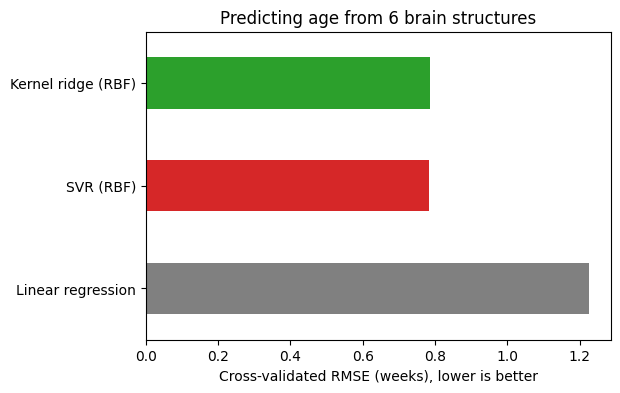

In [ ]:
results = pd.Series({'Linear regression': rmse_lin, 'SVR (RBF)': rmse_svr, 'Kernel ridge (RBF)': rmse_krr})
print(results.round(2).to_string())

results.plot.barh(color=['grey', 'tab:red', 'tab:green'])
plt.xlabel('Cross-validated RMSE (weeks), lower is better')
plt.title('Predicting age from 6 brain structures')
plt.show()

### Checking for bias

A good way to see *where* a model goes wrong is to plot **true age vs. predicted age**. A perfect model puts every point on the red diagonal line. If the points curve away from it, the model has a **bias**: it is systematically wrong for some babies.

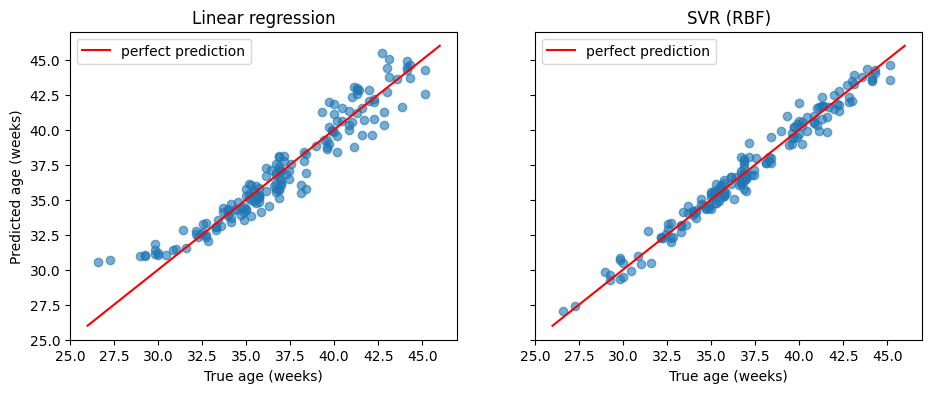

In [ ]:
best_svr = svr_grid.best_estimator_
lin6 = LinearRegression().fit(X6, y6)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, m, name in [(axes[0], lin6, 'Linear regression'), (axes[1], best_svr, 'SVR (RBF)')]:
    ax.scatter(y6, m.predict(X6), alpha=0.6)
    ax.plot([26, 46], [26, 46], 'r', label='perfect prediction')
    ax.set_xlabel('True age (weeks)')
    ax.set_title(name)
    ax.legend()
axes[0].set_ylabel('Predicted age (weeks)')
plt.show()

<details>
<summary><b>What should you notice?</b></summary>

For the youngest babies, linear regression tends to predict ages that are **too old** (points above the red line on the left), because a straight line cannot follow the curved growth of the brain. The kernel model follows the diagonal more closely, so it has **less bias**.
</details>

*A note on honesty:* the CV RMSE of the best grid-search setting is slightly optimistic, because we picked that setting by looking at the same scores. In a real project you would keep a separate **test set** aside and use it only once, at the very end, to report the final error.

---
# Summary

| Model | sklearn | Key settings | Use it when |
|---|---|---|---|
| Linear regression | `LinearRegression()` | none | the relationship is roughly a straight line; always try it first as a baseline |
| Polynomial regression | `PolynomialFeatures` + `LinearRegression` | `degree` | there is a gentle curve in one or two features |
| SVM classifier | `SVC()` | `kernel`, `C`, `gamma` | predicting a category; you want a maximum-margin boundary |
| SVM regressor | `SVR()` | `kernel`, `C`, `gamma`, `epsilon` | predicting a number while ignoring small errors |
| Kernel ridge regression | `KernelRidge()` | `kernel`, `alpha`, `gamma` | predicting a number with a flexible, smooth curve |

**Key ideas to remember**
* Judge models on **data they haven't seen**: use a test set or cross-validation.
* **Underfitting** = too simple (systematic errors). **Overfitting** = too flexible (follows the noise; training error low, CV error high).
* An SVM finds the boundary with the **widest margin**; only the **support vectors** matter.
* **C** trades margin width against mistakes. Small C is simpler; large C fits the training data harder.
* A **kernel** is a similarity measure that lets a linear method draw curves. **RBF** is the usual first choice, and **gamma** sets how wiggly it gets.
* **Scale your features** (`StandardScaler`) before using SVMs or kernels.
* Tune settings with **`GridSearchCV`**, and always compare against a simple baseline.

### Quick quiz

1. Your model has a training RMSE of 0.5 weeks and a CV RMSE of 3 weeks. What is going on?
2. You increase C in a linear SVM. What happens to the margin?
3. Which RBF setting would you change to make the boundary smoother?
4. In SVR, what happens to the support vectors when you make epsilon bigger?

<details>
<summary><b>Show answers</b></summary>

1. **Overfitting**: the model memorised the training data but does badly on new babies.
2. It gets **narrower**, because mistakes cost more, so the model squeezes the margin to avoid them.
3. **Decrease gamma** (and/or decrease C).
4. There are **fewer** of them, because more points fit inside the wider tube.
</details>

### Want more?
* Try the SVR and kernel ridge models with different pairs of brain structures.
* Try classifying term vs. preterm with all six structures instead of two.
* Look up **Lasso** and **Ridge** regression, which add penalties to linear regression to stop it overfitting when there are many features.